# 01 · Exploratory data analysis — OPSSAT-AD

**Goal:** understand the data before modelling, and find anything that could make results misleading.

This notebook only *displays* results produced by the project modules, so every figure in the report
can be regenerated from the command line:

```
python -m satelliteguard.data.download    # fetch + verify
python -m satelliteguard.data.validate    # data contract
python -m satelliteguard.data.episodes    # segment index + contiguous episodes
python -m satelliteguard.eda              # figures -> reports/figures/
python -m satelliteguard.evaluation.leakage_check
```

> Labels are segment-level *benchmark annotations*, not confirmed hardware faults, and channel IDs are opaque.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from satelliteguard import load_config

cfg = load_config()
P, FIG = cfg["paths"], cfg["paths"]["figures"]
dataset = pd.read_csv(P["raw"] / "dataset.csv")
index = pd.read_csv(P["processed"] / "segment_index.csv", parse_dates=["start", "end"])
audit = json.loads(P["audit"].read_text())
manifest = json.loads(P["manifest"].read_text())
show = lambda name: display(Image(filename=str(FIG / f"{name}.png")))
print(f"{len(dataset)} segments, {dataset.shape[1]} columns, {index['channel'].nunique()} channels")

2123 segments, 23 columns, 9 channels


## 1. Data provenance and contract
Files are checksum-verified against the Zenodo record; the data contract must pass before any modelling.

In [2]:
pd.DataFrame(manifest["files"])[["file", "size_bytes", "rows", "md5"]]

,file,size_bytes,rows,md5
0,LICENSE,1091,NaN,ea8befa9af2b37b7a54b5a16fc3712b0
1,dataset.csv,507550,2123.0,5246fdc5e4630a4cecbf7fb6bc8b795e
2,dataset_generator.ipynb,8089,NaN,f0cdeb8f965715d326ebeb625362b71e
3,modeling_examples.ipynb,7174,NaN,044eeff4bf3c767326e3ffd12c3b7a09
4,requirements.txt,169,NaN,252b98857695f9695589f90a590a49e6
5,segments.csv,18987091,303493.0,72f109630abb933a386106897a631188


In [3]:
pd.Series({k: "PASS" if v["passed"] else "FAIL" for k, v in audit["checks"].items()}, name="status").to_frame()

,status
segments_columns,PASS
dataset_required_columns,PASS
dataset_unique_segment_ids,PASS
dataset_no_nulls,PASS
segments_no_nulls,PASS
one_channel_target_split_per_segment,PASS
label_vs_anomaly_crosstab,PASS
segment_ids_match_between_files,PASS
target_split_channel_agree_between_files,PASS
split_counts_match_publisher,PASS


**Finding — the raw `label` column is meaningless.** It holds the constant string `"anomaly"` in all 303,493 rows
(it is a column name, not a class). The numeric `anomaly` field is the only target; `label` is excluded from everything.

In [4]:
audit["checks"]["label_vs_anomaly_crosstab"]["detail"]

{'0': {'anomaly': 203229}, '1': {'anomaly': 100264}}

## 2. Class balance

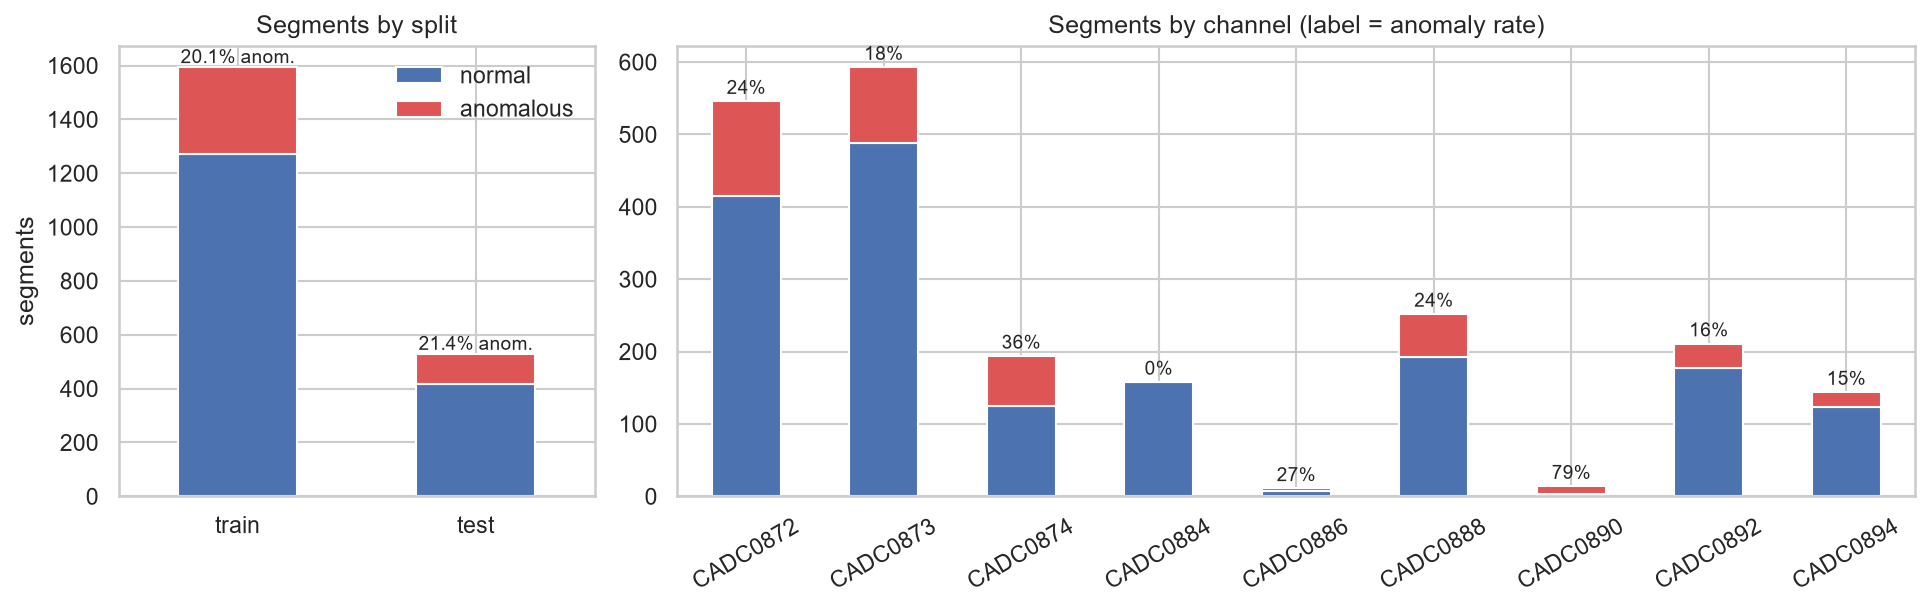

,segments,anomalies,rate
train,,,
0,529,113,0.214
1,1594,321,0.201


In [5]:
show("01_class_balance")
dataset.groupby("train")["anomaly"].agg(segments="size", anomalies="sum", rate="mean").round(3)

- About **20% of segments are anomalous** in both splits, so accuracy is a misleading metric (predicting
  "normal" always gives 80%). **PR-AUC** is the primary metric.
- Anomaly rate varies a lot by channel: **CADC0890 = 79%**, **CADC0884 = 0%**. Two channels (CADC0886, CADC0890)
  have fewer than 20 segments, so per-channel results there will be unstable and are reported separately.
- Risk: a model could learn "channel ⇒ anomaly". Section 6 checks this with a channel-only baseline.

## 3. Segment length, duration and sampling

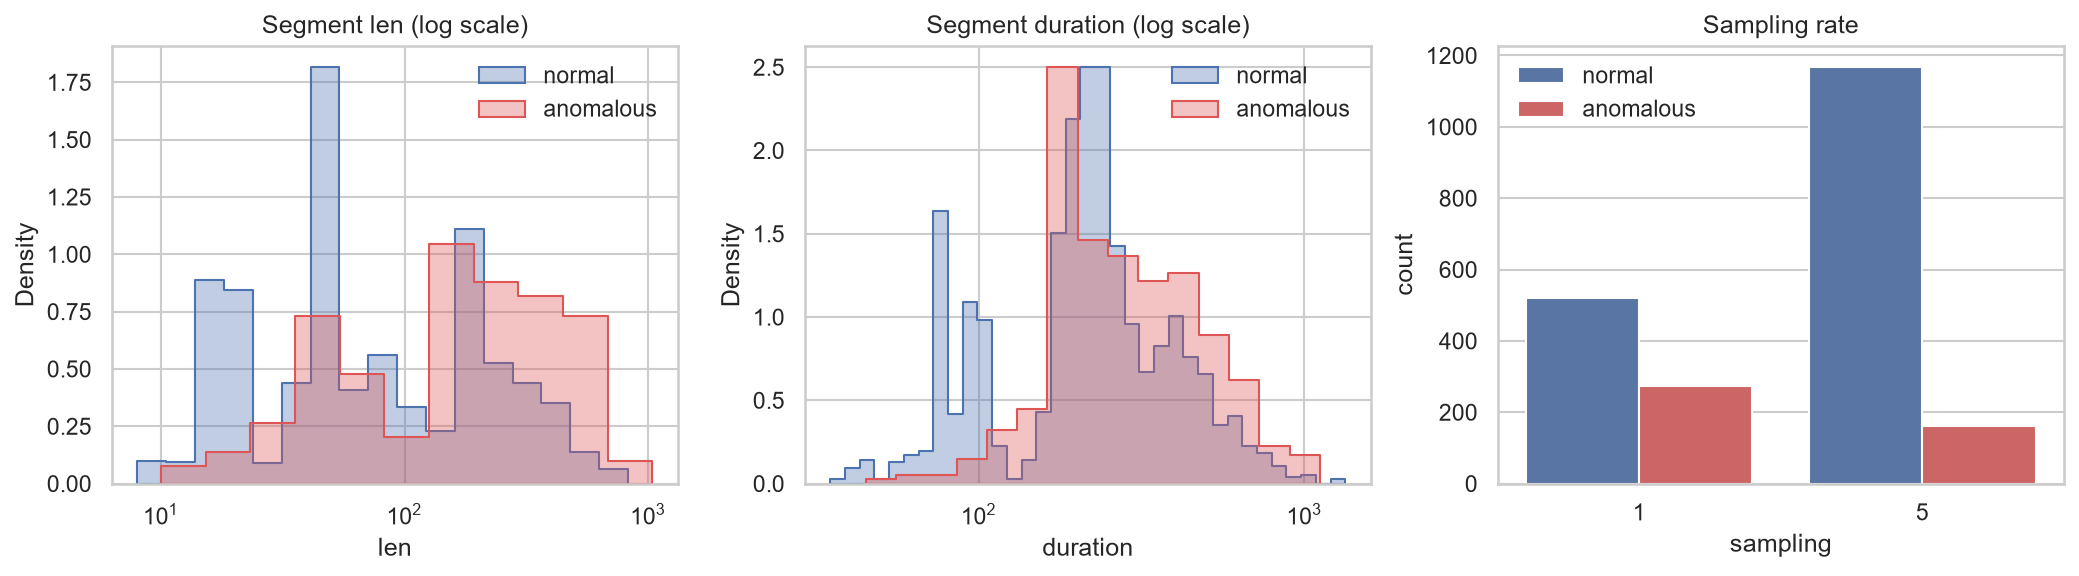

,len,duration
anomaly,,
0,54.0,220.0
1,184.5,266.0


In [6]:
show("03_length_duration_sampling")
dataset.groupby("anomaly")[["len", "duration"]].median()

Segments vary from 8 to 1,040 samples. Two sampling rates exist (1 s and 5 s). Length differs by class, so
length-based features carry signal — but length is also a property of how the publisher cut the segments, which
is a caveat worth stating in the report.

## 4. Features

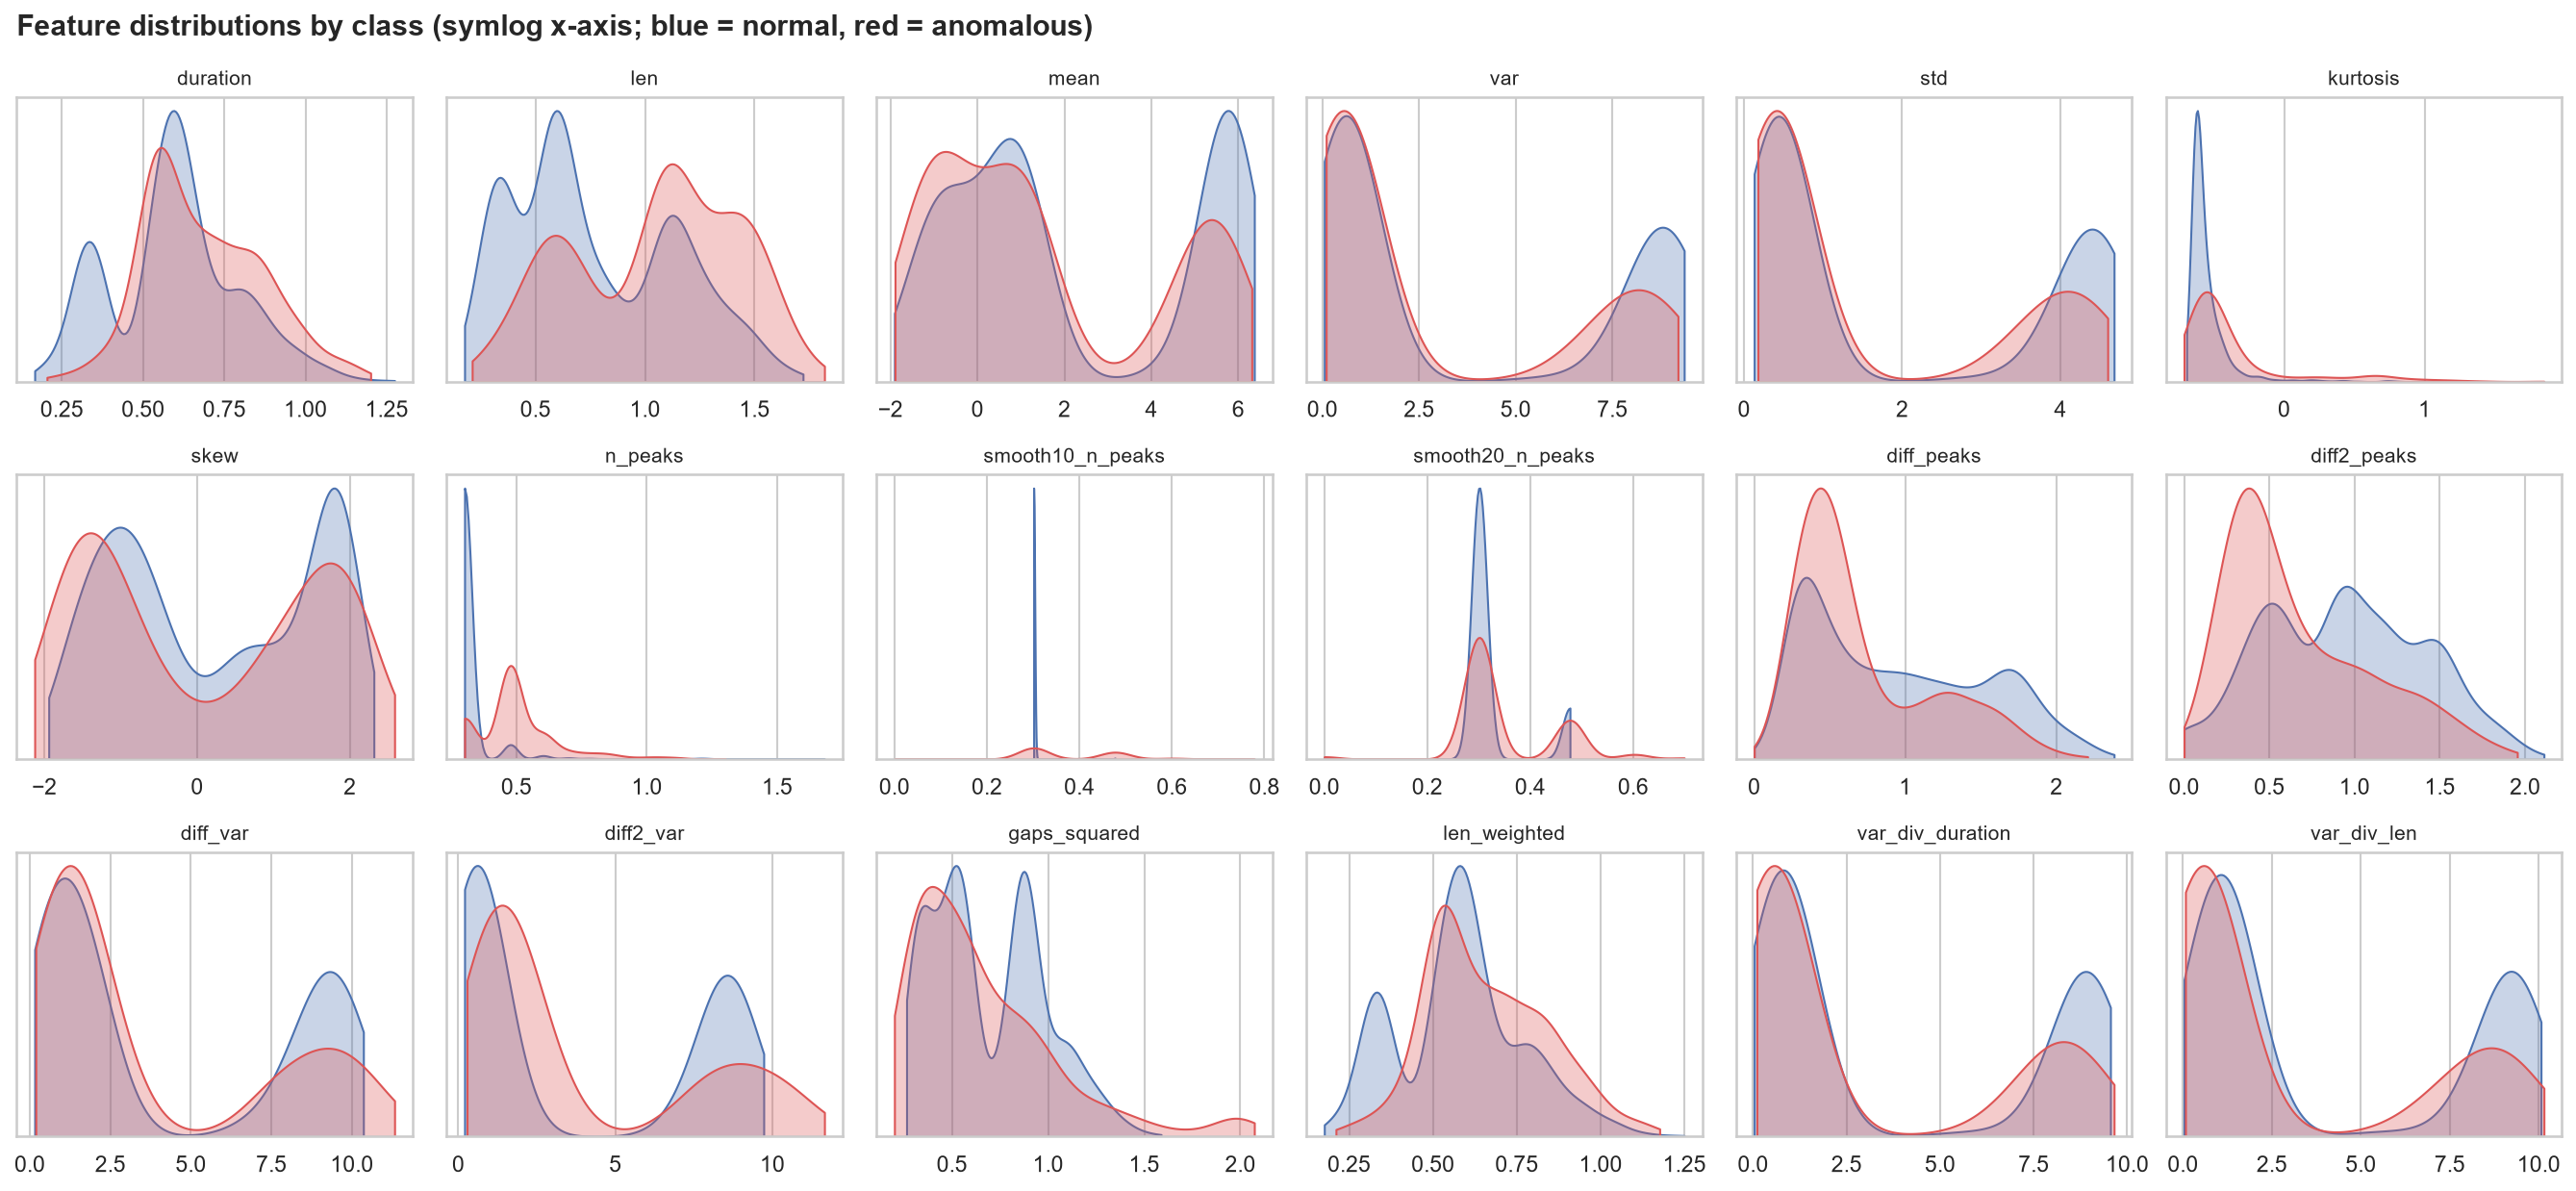

In [7]:
show("04_feature_distributions")

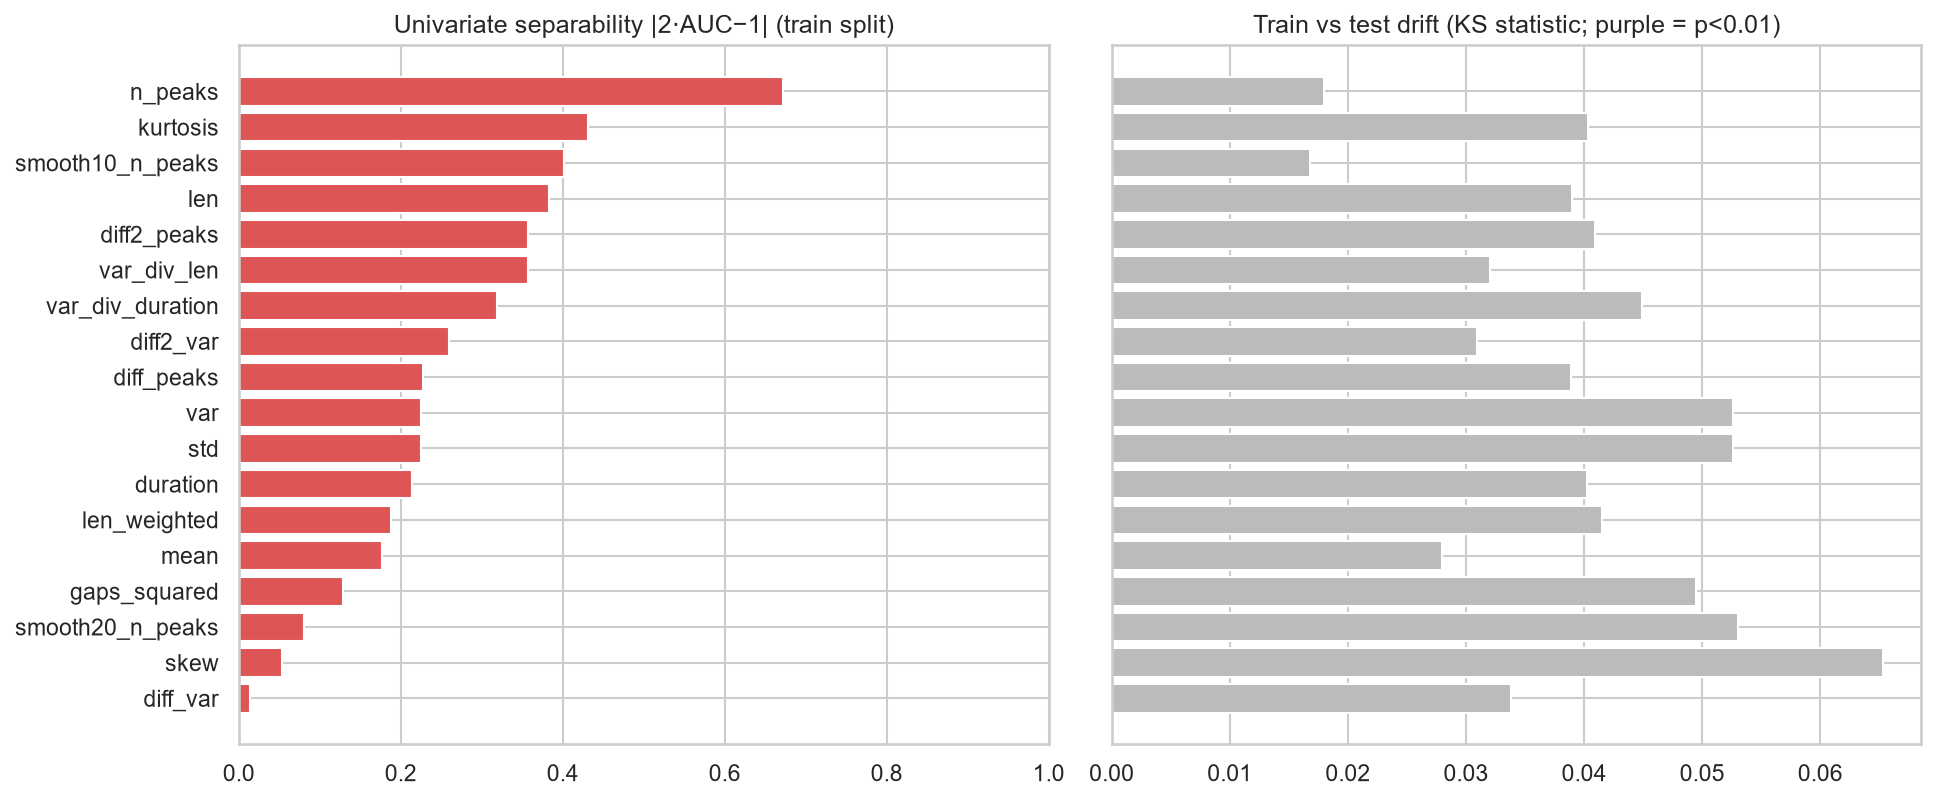

,feature,train_auc,auc_strength,train_test_ks,ks_pvalue
0,n_peaks,0.8358,0.6716,0.0179,0.9993
1,kurtosis,0.7156,0.4312,0.0404,0.5206
2,smooth10_n_peaks,0.7006,0.4013,0.0168,0.9998
3,len,0.6913,0.3826,0.0390,0.5655
4,diff2_peaks,0.3212,0.3576,0.0409,0.5032
5,var_div_len,0.3215,0.3571,0.0320,0.7953
6,var_div_duration,0.3407,0.3186,0.0449,0.3847
7,diff2_var,0.6298,0.2597,0.0309,0.8278
8,diff_peaks,0.3862,0.2276,0.0389,0.5693
9,var,0.3875,0.2250,0.0526,0.2119


In [8]:
show("06_separability_drift")
pd.read_csv(P["processed"] / "feature_screening.csv").head(10)

- **`n_peaks` is the strongest single feature** (|2·AUC−1| ≈ 0.67), followed by kurtosis and smoothed peak counts —
  consistent with the raw traces below, where anomalies show spikes and dropouts.
- **No significant train/test drift**: every KS statistic is below 0.07 and none is significant at p < 0.01.
  This is expected from an interleaved split (Section 5) — and is itself a hint that the split is not temporal.

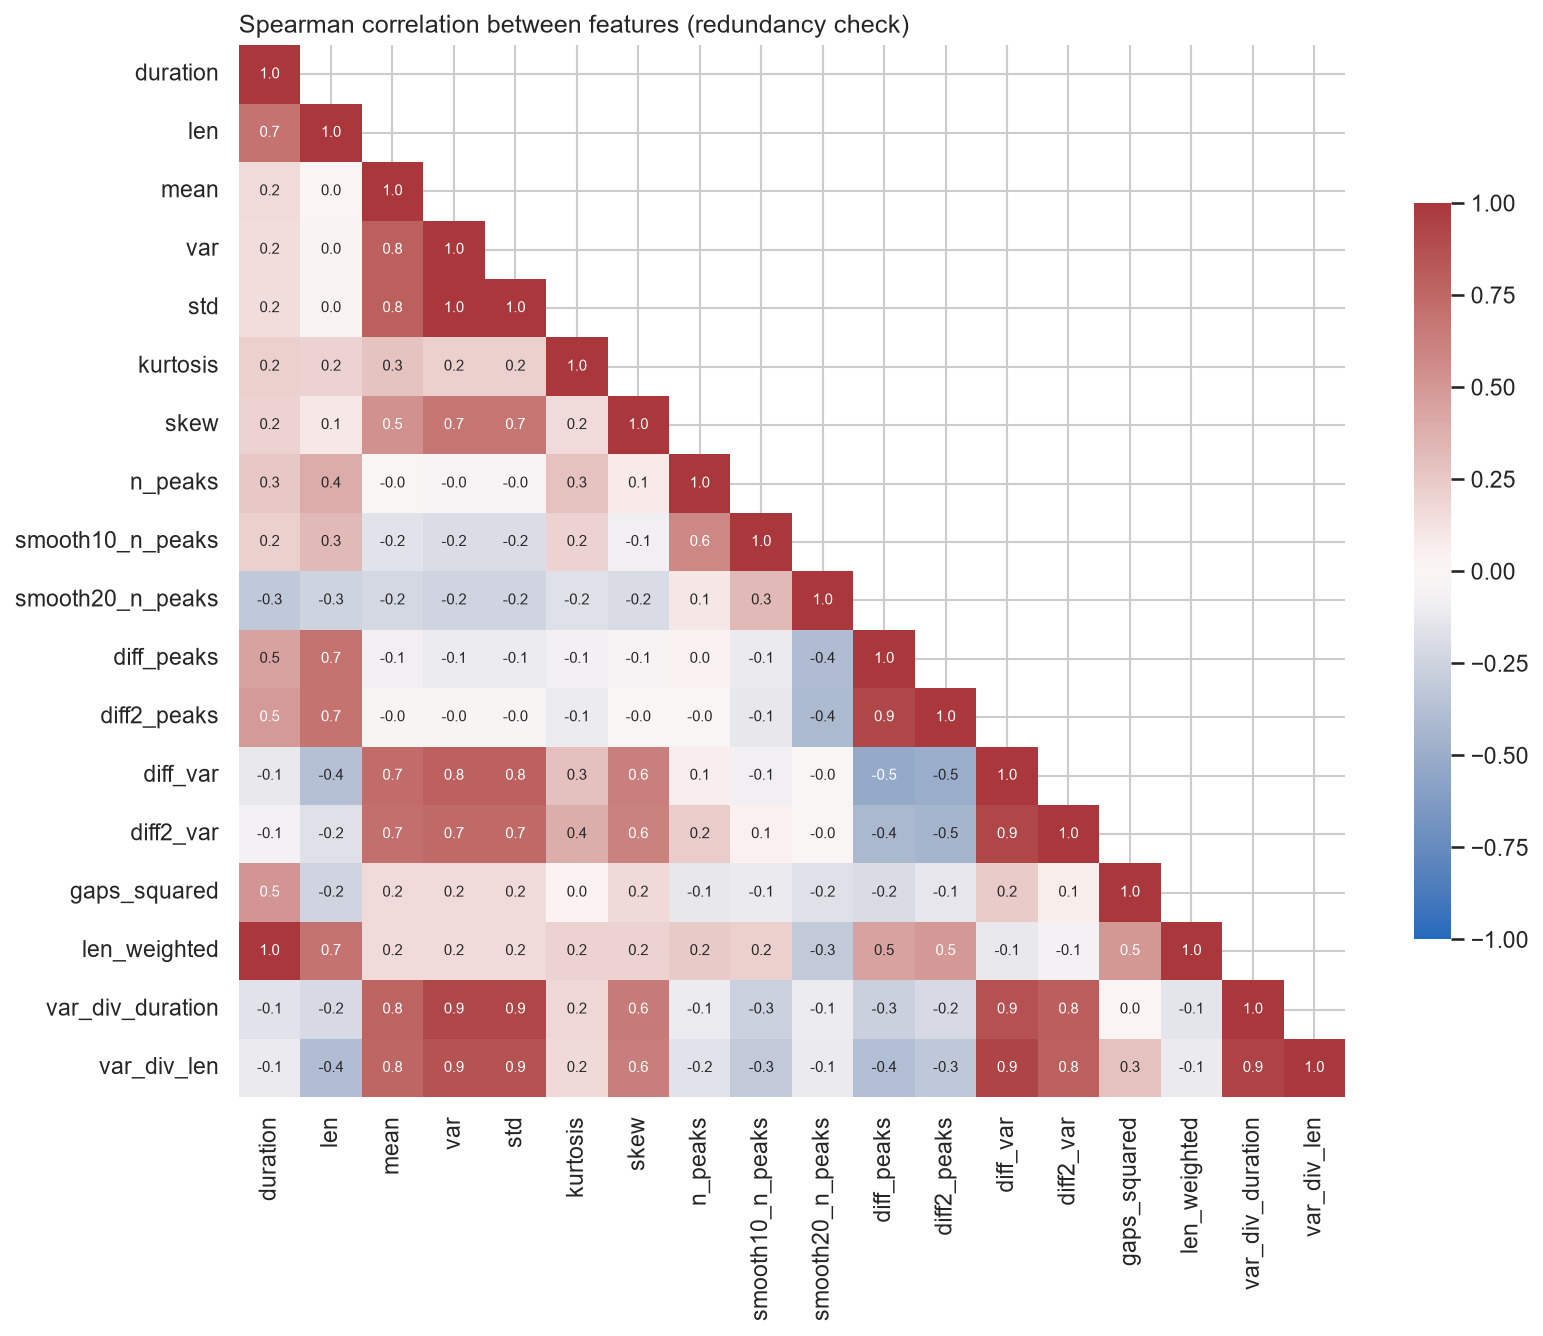

In [9]:
show("05_feature_correlation")

Several features are near-duplicates (`var`/`std`, `duration`/`len_weighted`, `var_div_len`/`var_div_duration`).
This is harmless for tree models but matters for the logistic baseline (unstable coefficients) — use regularisation
and do not read coefficients as independent effects.

## 5. Raw traces

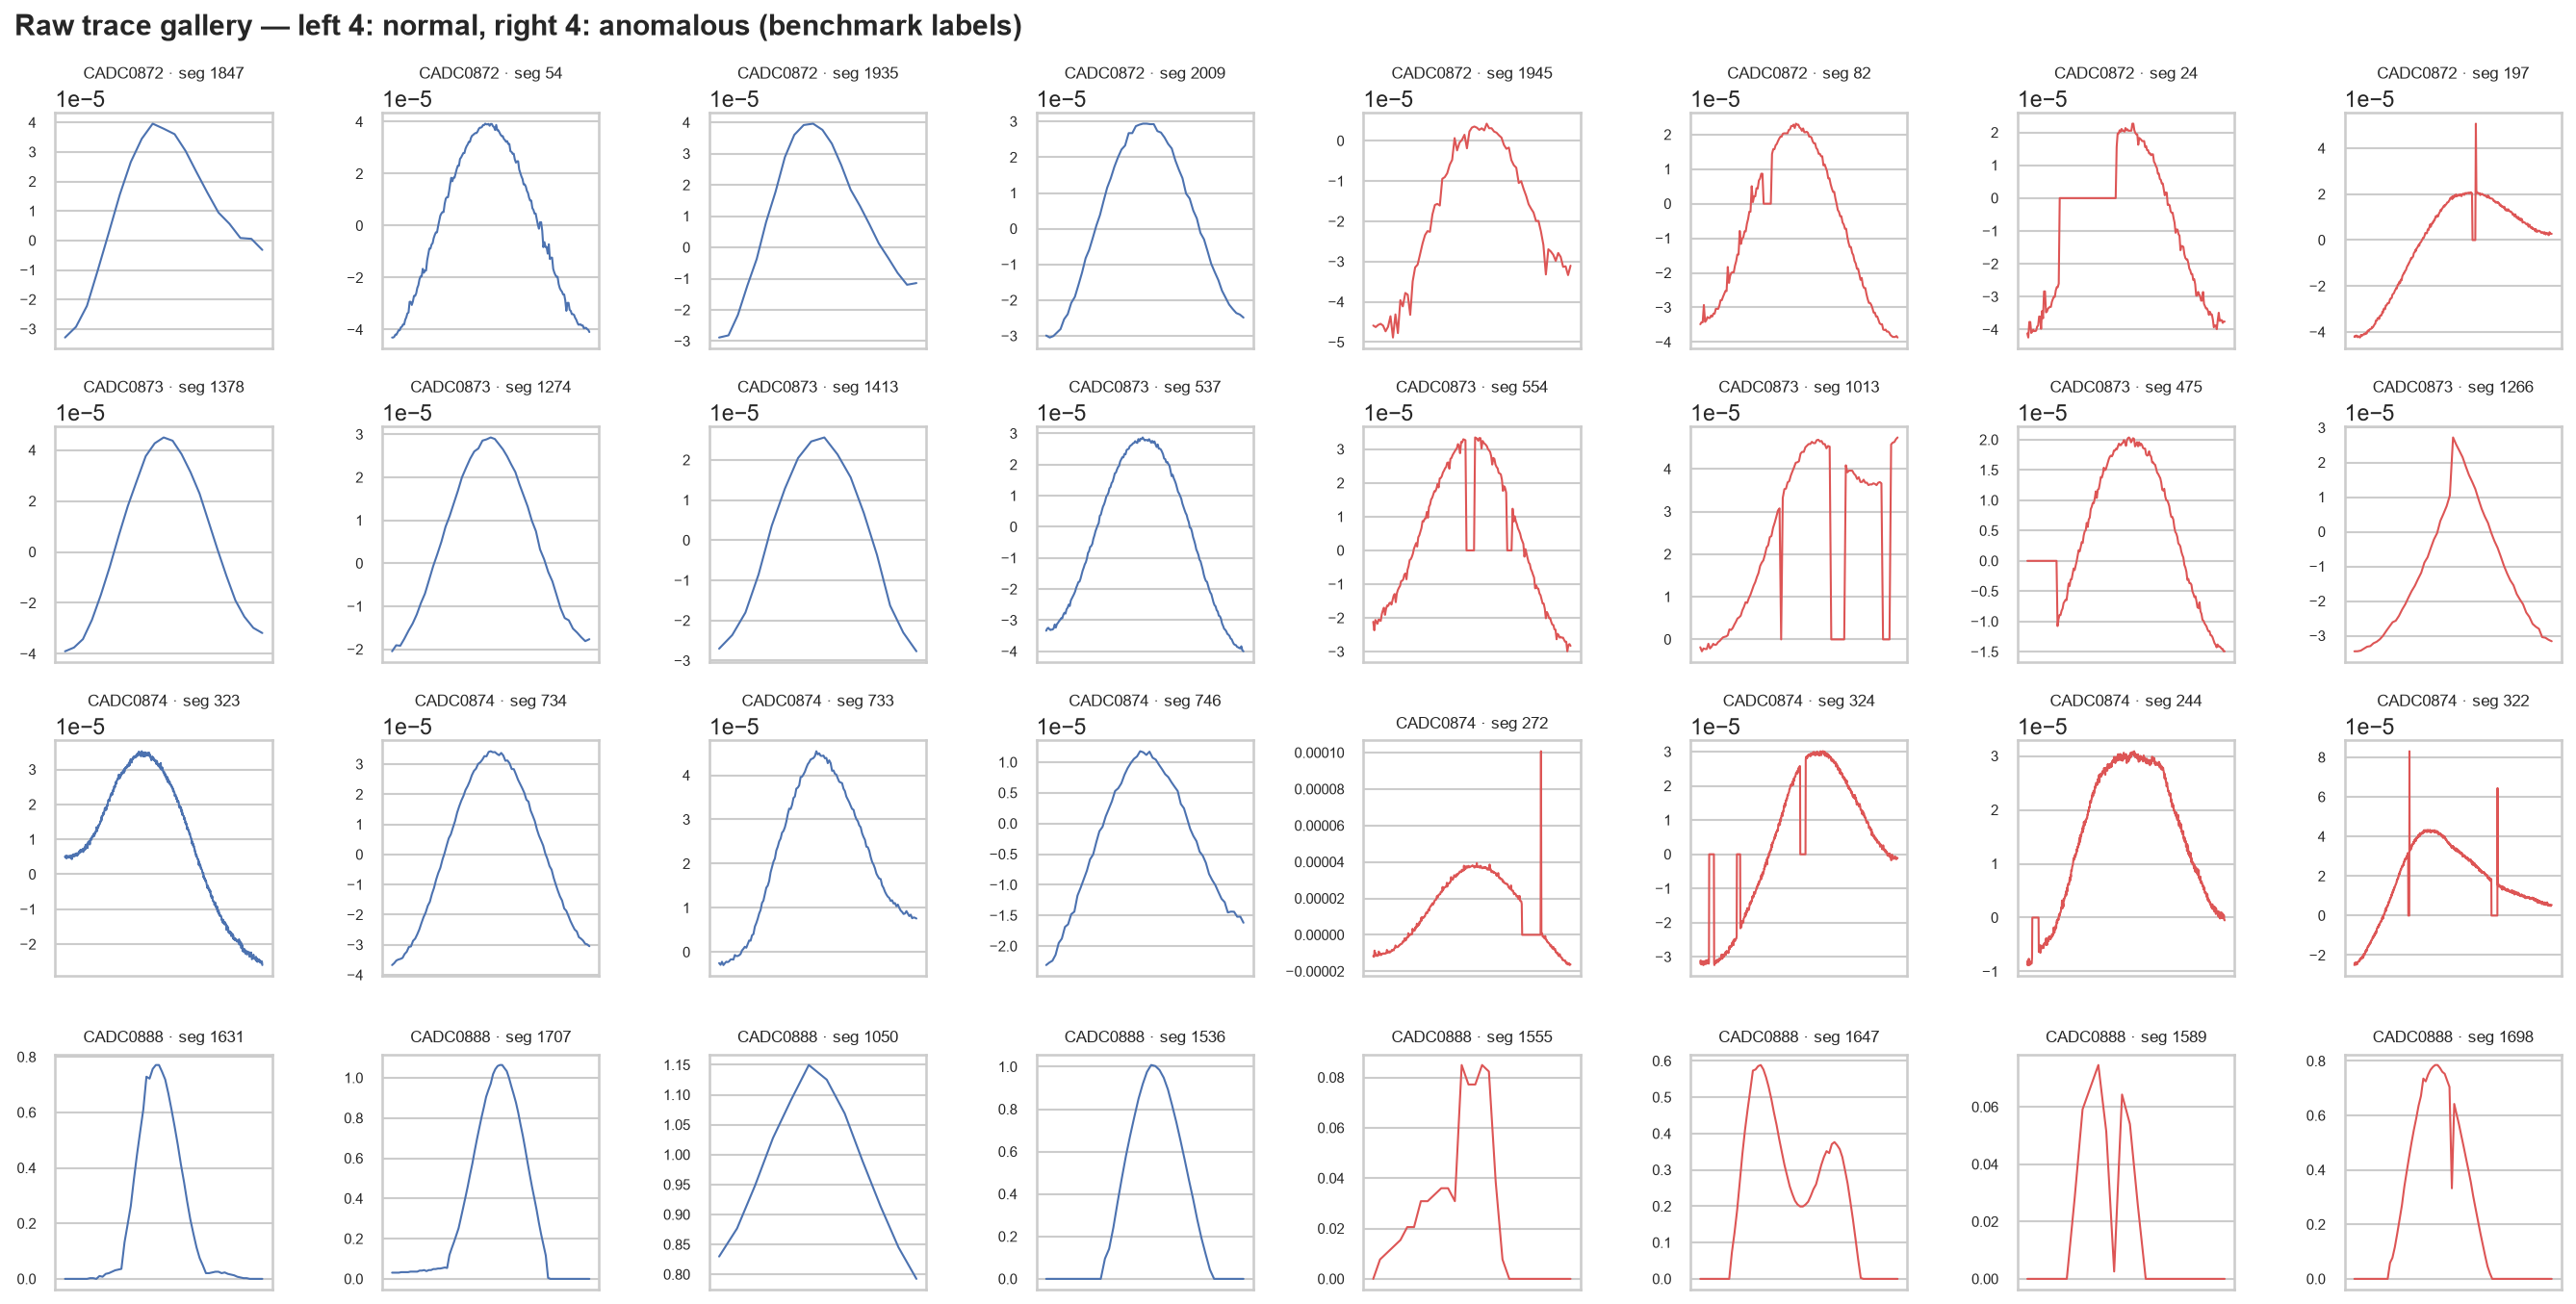

In [10]:
show("07_trace_gallery")

Normal segments are smooth arcs. Annotated anomalies show **dropouts to zero, isolated spikes, flat steps and
distorted shapes**. Summary statistics capture some of this (peaks, kurtosis), which is why a feature-based model is a
sensible primary track; a sequence model (stretch goal) could capture shape directly.

## 6. Neighbour leakage — the key methodological finding

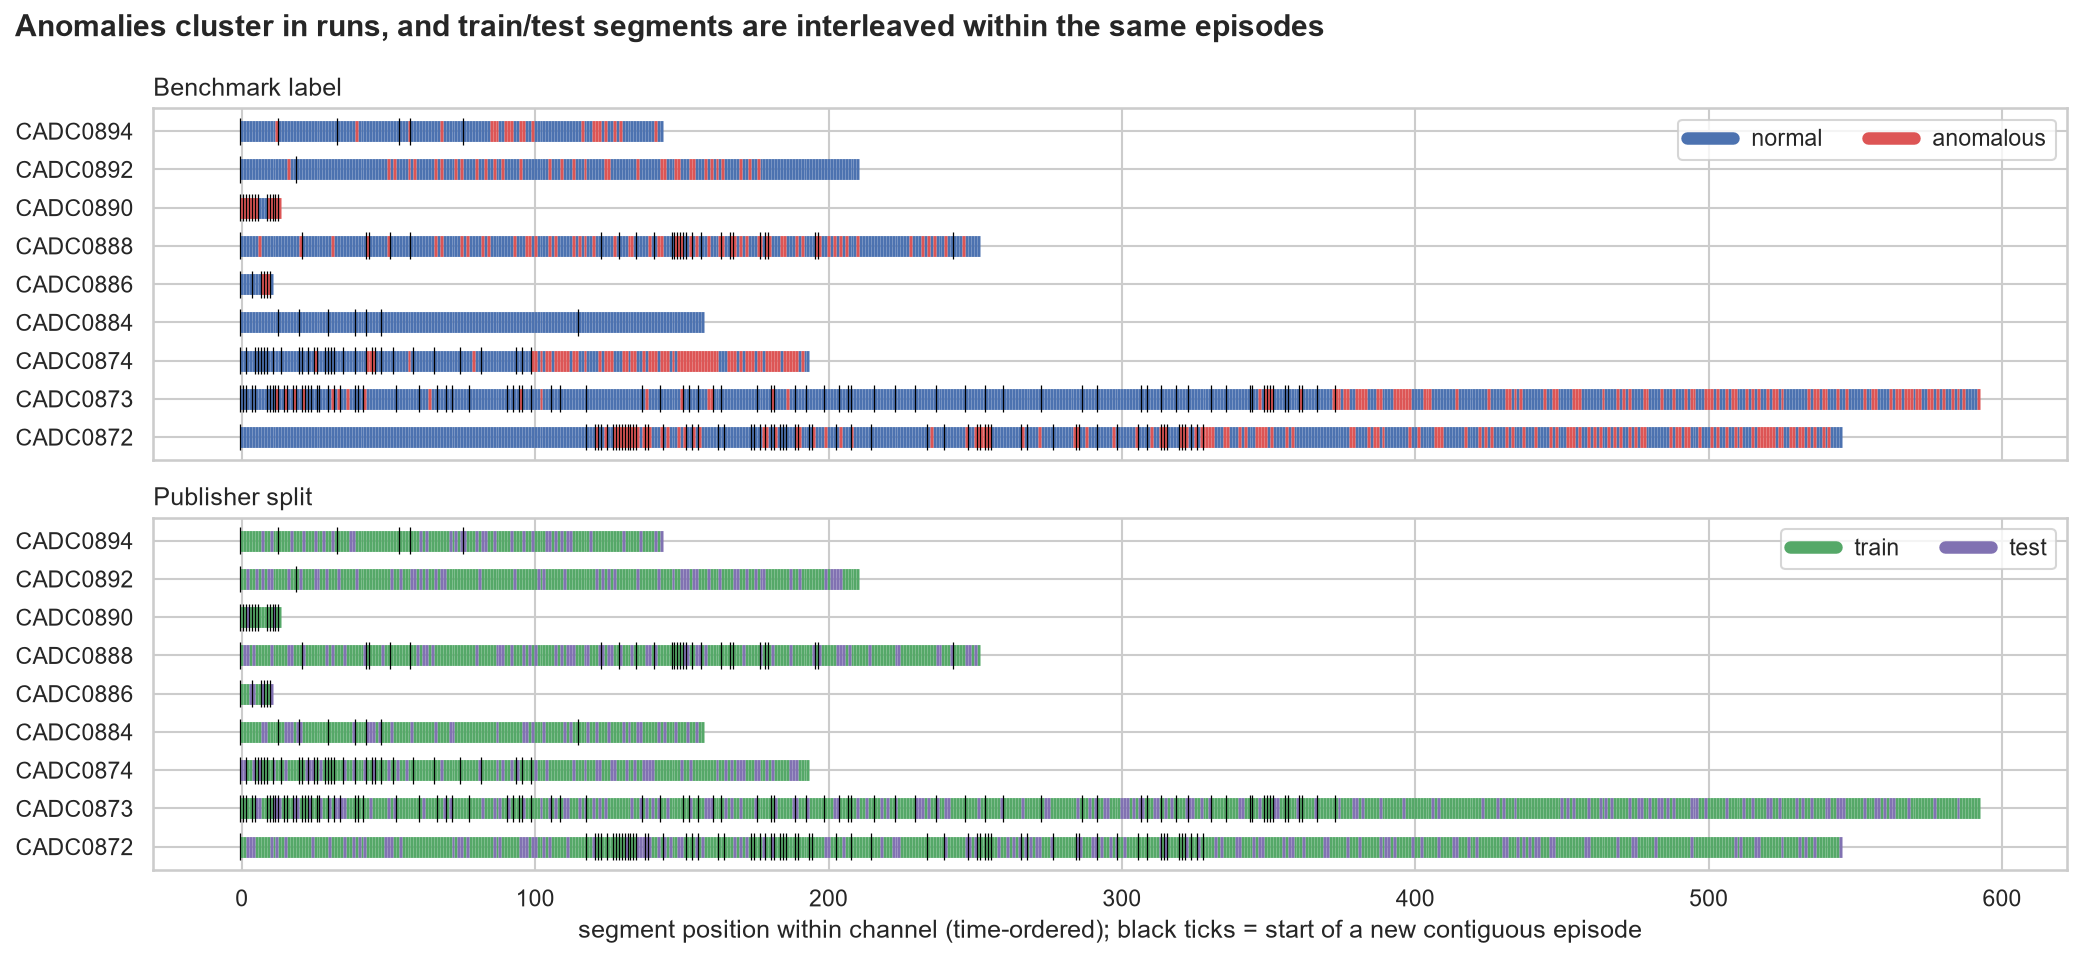

In [11]:
show("02_segment_timeline")

In [12]:
from satelliteguard.data.episodes import leakage_summary
pd.Series(leakage_summary(index), name="value").to_frame()

,value
n_episodes,243.000
episode_size_median,3.000
episode_size_max,220.000
episodes_spanning_both_splits,117.000
test_segments_touching_train,473.000
n_test_segments,529.000
p_anomaly_given_prev_anomaly,0.366
p_anomaly_given_prev_normal,0.163


**Segments are not independent.** They are back-to-back slices of continuous telemetry: the median gap to the
previous segment on the same channel is one sampling step. We group them into **243 contiguous episodes**
(gap ≤ 10 s).

- Anomalies cluster: P(anomalous | previous anomalous) = **0.37** vs **0.16** after a normal segment.
- The publisher split is interleaved: **473 of 529 test segments (89%) directly touch a training segment.**

**Consequence for validation.** If cross-validation assigns segments to folds independently, a validation segment's
almost-identical neighbour is in the training fold, and scores are inflated. The experiment below runs the *same*
fixed model under random vs episode-grouped CV (train split only — the frozen test is not touched):

In [13]:
lk = json.loads((P["metrics"].parent / "leakage_check.json").read_text())
pd.DataFrame({s: {k: f'{v["mean"]:.3f} ± {v["std"]:.3f}' for k, v in lk[s].items()} for s in ["random", "grouped"]})

,random,grouped
model_pr_auc,0.967 ± 0.013,0.931 ± 0.046
model_roc_auc,0.986 ± 0.006,0.969 ± 0.023
channel_only_pr_auc,0.283 ± 0.018,0.250 ± 0.050


- Random CV overstates PR-AUC by about **0.04** and understates its variance about **3.5×**.
- The **channel-only baseline** reaches only ~0.25–0.28 PR-AUC (prevalence 0.20): the signal features, not channel
  identity, drive performance.

**Decisions taken:**
1. All model selection, tuning and threshold choice use **episode-grouped CV** (`StratifiedGroupKFold`).
2. The publisher test split stays the **frozen final test**, so results stay comparable with the published benchmark —
   but the report states that it shares episodes with training and is therefore *optimistic* about generalisation to
   unseen time periods.
3. The channel-only baseline is kept as a reference row in every results table.

## Summary

| Question | Answer |
|---|---|
| Data verified? | Yes — checksums, schema, split counts, one label/channel/split per segment, monotonic timestamps |
| Target | numeric `anomaly` (raw `label` is a constant, ignored) |
| Imbalance | ~20% anomalous → PR-AUC primary |
| Train/test drift | none detected |
| Strongest features | peak counts, kurtosis, length-normalised variance |
| Main risk | neighbour leakage → episode-grouped CV; frozen-test caveat in report |